# Proyecto final Olist

## Versión en Python del análisis de órdenes, entregas y conciliación de pagos

Equivalente de `Proyecto_Final_Olist_FINAL.Rmd`. El script de R prepara las tablas y las exporta; las cuatro gráficas del tablero (conteo diario, tiempos ponderados, conciliación pago–costo y medios de pago) se reconstruyen aquí a partir de esas mismas reglas.

### Integrantes
- Laura Berenice Badillo Santos
- Eduardo Sánchez Benítez
- Juan Alberto Jaimes Romero
- Juan Manuel Sóstenes Sánchez
- Angel Noriega Cabrera


## 1. Preparación

Se usan los nueve archivos públicos de Olist. Esta libreta está en `edas_preliminares/`. Busca los CSV en `OLIST_DATA_DIR`, en `~/projects/work-at-olist-data/datasets` y, subiendo desde esa carpeta o desde la raíz del repositorio, en `work-at-olist-data/datasets`. No modifica los CSV.

Las reseñas se cargan en el script de R y no entran en ningún cálculo posterior; aquí no se leen. De la geolocalización solo se usan el prefijo postal y las coordenadas.


In [14]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
    "axes.titlesize": 11,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.unicode_minus": False,
})

MESES = ["ene", "feb", "mar", "abr", "may", "jun",
         "jul", "ago", "sep", "oct", "nov", "dic"]


def localizar_directorio(requeridos):
    candidatos = []
    definida = os.environ.get("OLIST_DATA_DIR")
    if definida:
        candidatos.append(Path(definida).expanduser())
    candidatos.append(Path("~/projects/work-at-olist-data/datasets").expanduser())
    semillas = [Path.cwd().resolve()]
    anidada = semillas[0] / "edas_preliminares"
    if anidada.is_dir():
        semillas.append(anidada)
    for semilla in semillas:
        for base in (semilla, *semilla.parents):
            candidatos.extend([
                base / "work-at-olist-data" / "datasets",
                base / "datasets",
                base.parent / "work-at-olist-data" / "datasets",
            ])
    vistos = set()
    for ruta in candidatos:
        clave = str(ruta)
        if clave in vistos:
            continue
        vistos.add(clave)
        if all((ruta / nombre).is_file() for nombre in requeridos):
            return ruta
    raise FileNotFoundError(
        "No encontré los CSV de Olist. Define OLIST_DATA_DIR o clona "
        "https://github.com/olist/work-at-olist-data junto al proyecto."
    )


def leer(nombre, fechas=None):
    ruta = DATA_DIR / nombre
    preview = pd.read_csv(ruta, nrows=0)
    texto = {
        columna: "string"
        for columna in preview.columns
        if columna.endswith("_id")
        or columna.endswith("_zip_code_prefix")
        or columna == "customer_unique_id"
    }
    return pd.read_csv(ruta, dtype=texto, parse_dates=fechas)


REQUERIDOS = (
    "olist_orders_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_order_payments_dataset.csv",
    "olist_customers_dataset.csv",
    "olist_products_dataset.csv",
    "olist_sellers_dataset.csv",
    "product_category_name_translation.csv",
    "olist_geolocation_dataset.csv",
)
DATA_DIR = localizar_directorio(REQUERIDOS)

ordenes = leer("olist_orders_dataset.csv", fechas=[
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
])
articulos = leer("olist_order_items_dataset.csv", fechas=["shipping_limit_date"])
pagos = leer("olist_order_payments_dataset.csv")
clientes = leer("olist_customers_dataset.csv")
productos = leer("olist_products_dataset.csv")
vendedores = leer("olist_sellers_dataset.csv")
traduccion = leer("product_category_name_translation.csv")
geolocalizacion = pd.read_csv(
    DATA_DIR / "olist_geolocation_dataset.csv",
    dtype={"geolocation_zip_code_prefix": "string"},
    usecols=["geolocation_zip_code_prefix", "geolocation_lat", "geolocation_lng"],
)

print("Directorio de datos:", DATA_DIR)
for nombre, tabla in {
    "ordenes": ordenes,
    "articulos": articulos,
    "pagos": pagos,
    "clientes": clientes,
    "productos": productos,
    "vendedores": vendedores,
    "traduccion": traduccion,
    "geolocalizacion": geolocalizacion,
}.items():
    print(f"{nombre:18} {tabla.shape[0]:8,} filas   {tabla.shape[1]:2} columnas")


Directorio de datos: /home/alberto/projects/work-at-olist-data/datasets
ordenes              99,441 filas    8 columnas
articulos           112,650 filas    7 columnas
pagos               103,886 filas    5 columnas
clientes             99,441 filas    5 columnas
productos            32,951 filas    9 columnas
vendedores            3,095 filas    4 columnas
traduccion               71 filas    2 columnas
geolocalizacion    1,000,163 filas    3 columnas


## 2. Contexto y preguntas

Olist conecta comercios pequeños con canales de venta en línea. Tras la compra, el vendedor prepara el pedido y un socio logístico lo entrega. Los datos son operaciones reales anonimizadas.

Este cuaderno responde las preguntas que el script de R sí calcula:

- ¿La base de órdenes está completa y hay identificadores duplicados? ¿Cómo se reparten los estatus?
- ¿Cuál es el tiempo estimado de entrega, el tiempo real y los días de retraso de las órdenes entregadas? ¿Cómo cambian esos tiempos, en promedio simple y ponderado por el importe, según la fecha de compra?
- ¿El importe pagado coincide con el precio de los artículos más el envío? ¿Qué órdenes no tienen pago o no tienen costo?
- ¿Qué tan completa está la categoría de los productos y cómo se agrupan en categorías generales?
- ¿Cómo se reparten los artículos entre regiones de Brasil? ¿El peso del producto se relaciona con el costo de envío? ¿Qué distancia lineal aproximada hay entre el código postal del cliente y el del vendedor?

Las gráficas del tablero que acompañan este archivo responden, además, el conteo diario de órdenes entregadas y el medio y el plazo de pago de las órdenes cuya conciliación no cuadra. Esas figuras salen de las tablas que el script de R exporta (`Serie_promedios` y el desglose de pagos); el R no las dibuja.


## 3. Calidad y estatus de las órdenes

Se revisan faltantes y duplicados en `order_id` y `customer_id`. En Olist, `customer_id` identifica al cliente dentro de una orden; el cliente a lo largo del tiempo es `customer_unique_id`.


,porcentaje_faltante
order_delivered_customer_date,2.98
order_delivered_carrier_date,1.79
order_approved_at,0.16
order_id,0.00
order_purchase_timestamp,0.00
order_status,0.00
customer_id,0.00
order_estimated_delivery_date,0.00


Filas: 99,441
order_id duplicados: 0
customer_id duplicados: 0


,order_status,ordenes,porcentaje
3,delivered,96478,97.020344
6,shipped,1107,1.113223
1,canceled,625,0.628513
7,unavailable,609,0.612423
4,invoiced,314,0.315765
5,processing,301,0.302692
2,created,5,0.005028
0,approved,2,0.002011


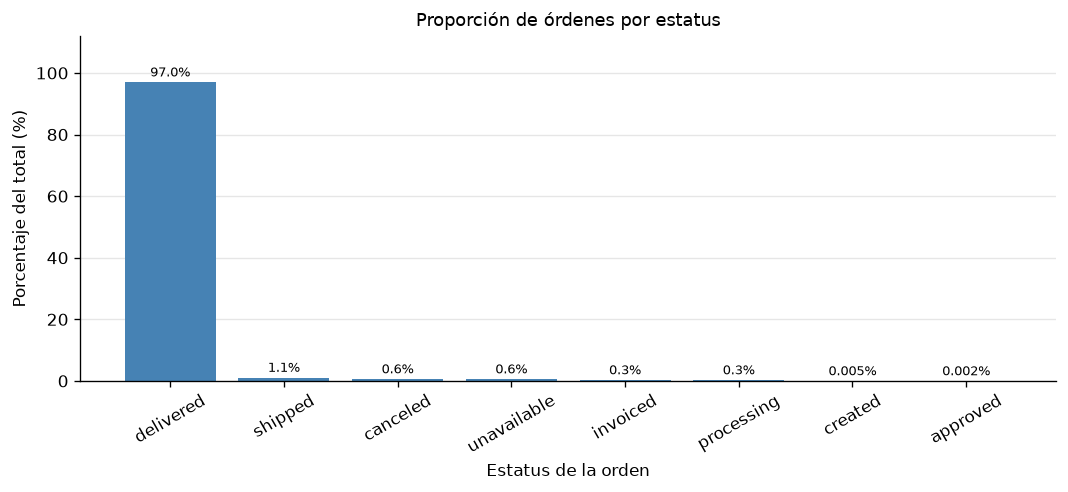

In [15]:
faltantes_ordenes = (ordenes.isna().mean() * 100).round(2).sort_values(ascending=False)
display(faltantes_ordenes.to_frame("porcentaje_faltante"))

print("Filas:", f"{len(ordenes):,}")
print("order_id duplicados:", int(ordenes["order_id"].duplicated().sum()))
print("customer_id duplicados:", int(ordenes["customer_id"].duplicated().sum()))

proporcion_estatus = (
    ordenes.groupby("order_status", as_index=False)
    .size()
    .rename(columns={"size": "ordenes"})
)
proporcion_estatus["porcentaje"] = proporcion_estatus["ordenes"] / len(ordenes) * 100
proporcion_estatus = proporcion_estatus.sort_values("porcentaje", ascending=False)
display(proporcion_estatus)

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(
    proporcion_estatus["order_status"],
    proporcion_estatus["porcentaje"],
    color="steelblue",
)
for etiqueta, altura in zip(proporcion_estatus["order_status"], proporcion_estatus["porcentaje"]):
    if altura >= 1:
        texto = f"{altura:.1f}%"
    elif altura >= 0.1:
        texto = f"{altura:.1f}%"
    else:
        texto = f"{altura:.3f}%"
    ax.text(etiqueta, altura + 0.8, texto, ha="center", va="bottom", fontsize=8)
ax.set_ylim(0, 112)
ax.set_ylabel("Porcentaje del total (%)")
ax.set_xlabel("Estatus de la orden")
ax.set_title("Proporción de órdenes por estatus")
ax.tick_params(axis="x", rotation=30)
ax.yaxis.grid(True, color="#E6E6E6")
ax.set_axisbelow(True)
fig.tight_layout()
display(fig)
plt.close(fig)


## 4. Tiempos de entrega

El cálculo usa solo órdenes `delivered`, igual que el script de R. Las marcas de tiempo se cortan al día (`as.Date` en R): el tiempo de entrega es la diferencia de fechas, no de horas.

Hay entregas marcadas como realizadas sin fecha de entrega al cliente o al transportista. Esas fechas se imputan con el promedio de las órdenes compradas el mismo día. Si un día entero no tuviera ninguna fecha observada, el hueco se conservaría. La fecha estimada no se imputa.

El retraso del script de R es cero cuando la entrega ocurre en o antes de la fecha estimada, y la diferencia positiva cuando llega después. No es un retraso con signo.


In [16]:
ordenes_entregadas = ordenes.loc[ordenes["order_status"] == "delivered"].copy()
columnas_fecha = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for columna in columnas_fecha:
    ordenes_entregadas[columna] = ordenes_entregadas[columna].dt.normalize()

faltantes_antes = ordenes_entregadas[columnas_fecha].isna().sum()
display(faltantes_antes.to_frame("faltantes_antes_de_imputar"))


def imputar_media_del_dia(serie):
    return serie.fillna(serie.mean())


for columna in ("order_delivered_customer_date", "order_delivered_carrier_date"):
    ordenes_entregadas[columna] = (
        ordenes_entregadas.groupby("order_purchase_timestamp")[columna]
        .transform(imputar_media_del_dia)
    )

faltantes_despues = ordenes_entregadas[
    ["order_delivered_customer_date", "order_delivered_carrier_date", "order_estimated_delivery_date"]
].isna().sum()
display(faltantes_despues.to_frame("faltantes_despues_de_imputar"))

compra = ordenes_entregadas["order_purchase_timestamp"]
estimada = ordenes_entregadas["order_estimated_delivery_date"]
real = ordenes_entregadas["order_delivered_customer_date"]
ordenes_entregadas["tiempo_estimado_dias"] = (estimada - compra).dt.total_seconds() / 86400
ordenes_entregadas["tiempo_entrega_dias"] = (real - compra).dt.total_seconds() / 86400
retraso_firmado = (real - estimada).dt.total_seconds() / 86400
ordenes_entregadas["dias_de_retraso"] = np.where(retraso_firmado > 0, retraso_firmado, 0.0)
ordenes_entregadas["retraso_firmado"] = retraso_firmado

display(ordenes_entregadas[
    ["tiempo_estimado_dias", "tiempo_entrega_dias", "dias_de_retraso", "retraso_firmado"]
].describe().round(2))


,faltantes_antes_de_imputar
order_purchase_timestamp,0
order_approved_at,14
order_delivered_carrier_date,2
order_delivered_customer_date,8
order_estimated_delivery_date,0


,faltantes_despues_de_imputar
order_delivered_customer_date,0
order_delivered_carrier_date,0
order_estimated_delivery_date,0


,tiempo_estimado_dias,tiempo_entrega_dias,dias_de_retraso,retraso_firmado
count,96478.00,96478.00,96478.00,96478.00
mean,24.37,12.50,0.72,-11.88
std,8.76,9.55,4.65,10.18
min,3.00,0.00,0.00,-147.00
25%,19.00,7.00,0.00,-17.00
50%,24.00,10.00,0.00,-12.00
75%,29.00,16.00,0.00,-7.00
max,156.00,210.00,188.00,188.00


## 5. Pago contra costo de la orden

`pago_realizado` es la suma de `payment_value` de la orden. `costo` es la suma de `price + freight_value` de sus artículos. La diferencia del script de R es esa resta redondeada a pesos enteros: un desfase menor a 0.50 queda en cero y cuenta como sin diferencia.

`pago_consolidado` usa el pago observado y, solo si la orden no tiene registro de pago, el costo de artículos y envío. Sirve de peso para los promedios de entrega. No reescribe la tabla de pagos.

El tablero separa dos banderas. La primera llama «con diferencias» tanto al desfase redondeado distinto de cero como a la orden a la que le falta el pago o el costo. La segunda parte ese grupo en «con diferencias» y «con valores faltantes».


Órdenes sin registro de pago: 1
Órdenes sin registro de costo: 775
Órdenes sin diferencia calculable: 776
Diferencia redondeada igual a 0: 98347
Diferencia redondeada distinta de 0: 318


,pago_realizado,costo
0.00,0.00,9.59
0.25,62.01,61.99
0.50,105.29,105.29
0.75,176.97,176.88
1.00,13664.08,13664.08


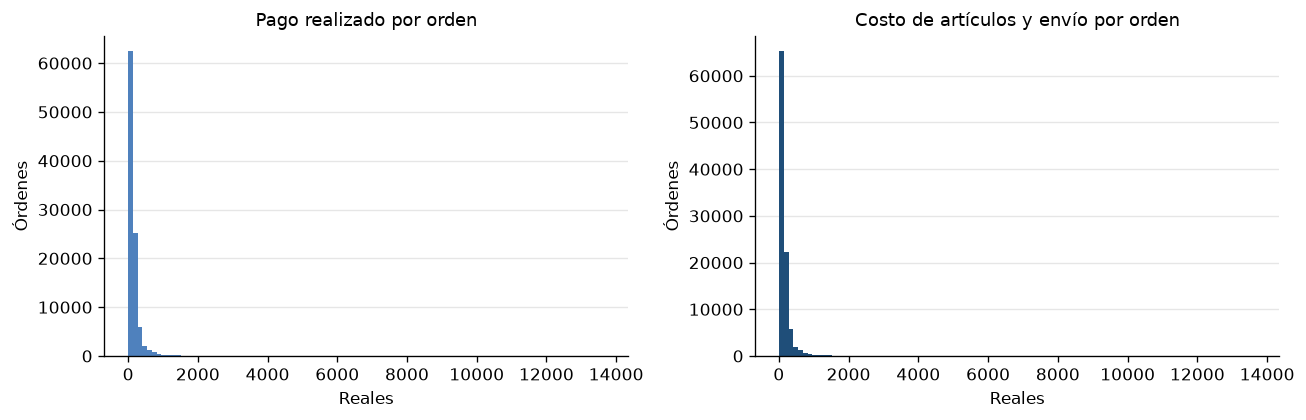

Entregadas sin pago consolidado: 0


In [17]:
pago_por_orden = (
    pagos.groupby("order_id", as_index=False)
    .agg(pago_realizado=("payment_value", "sum"))
)
articulos = articulos.copy()
articulos["costo_total"] = articulos["price"] + articulos["freight_value"]
costo_por_orden = (
    articulos.groupby("order_id", as_index=False)
    .agg(costo=("costo_total", "sum"))
)

comparacion = pago_por_orden.merge(costo_por_orden, on="order_id", how="outer")
comparacion["diferencia"] = (comparacion["pago_realizado"] - comparacion["costo"]).round(0)
comparacion["pago_consolidado"] = comparacion["pago_realizado"].where(
    comparacion["pago_realizado"].notna(),
    comparacion["costo"],
)

print("Órdenes sin registro de pago:", int(comparacion["pago_realizado"].isna().sum()))
print("Órdenes sin registro de costo:", int(comparacion["costo"].isna().sum()))
print("Órdenes sin diferencia calculable:", int(comparacion["diferencia"].isna().sum()))
print("Diferencia redondeada igual a 0:", int((comparacion["diferencia"] == 0).sum()))
print("Diferencia redondeada distinta de 0:", int((comparacion["diferencia"].notna() & comparacion["diferencia"].ne(0)).sum()))

cuantiles = pd.DataFrame({
    "pago_realizado": pago_por_orden["pago_realizado"].quantile([0, 0.25, 0.5, 0.75, 1]),
    "costo": costo_por_orden["costo"].quantile([0, 0.25, 0.5, 0.75, 1]),
})
display(cuantiles.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(pago_por_orden["pago_realizado"], bins=100, color="#4F81BD")
axes[0].set_title("Pago realizado por orden")
axes[0].set_xlabel("Reales")
axes[0].set_ylabel("Órdenes")
axes[1].hist(costo_por_orden["costo"], bins=100, color="#1F4E79")
axes[1].set_title("Costo de artículos y envío por orden")
axes[1].set_xlabel("Reales")
axes[1].set_ylabel("Órdenes")
for eje in axes:
    eje.yaxis.grid(True, color="#E6E6E6")
    eje.set_axisbelow(True)
fig.tight_layout()
display(fig)
plt.close(fig)

ordenes_entregadas = ordenes_entregadas.merge(
    comparacion[["order_id", "pago_realizado", "costo", "diferencia", "pago_consolidado"]],
    on="order_id",
    how="left",
)
print("Entregadas sin pago consolidado:", int(ordenes_entregadas["pago_consolidado"].isna().sum()))

comparacion_ordenes = ordenes[
    ["order_id", "order_status", "order_purchase_timestamp"]
].merge(comparacion, on="order_id", how="left")
comparacion_ordenes["fecha_compra"] = comparacion_ordenes["order_purchase_timestamp"].dt.normalize()
comparacion_ordenes["bandera"] = np.where(
    comparacion_ordenes["diferencia"].isna() | comparacion_ordenes["diferencia"].ne(0),
    "Con diferencias",
    "Sin diferencias",
)
comparacion_ordenes["bandera_detalle"] = np.where(
    comparacion_ordenes["diferencia"].isna(),
    "Con valores faltantes",
    np.where(comparacion_ordenes["diferencia"].ne(0), "Con diferencias", "Sin diferencias"),
)


## 6. Serie diaria de entregas

Para cada fecha de compra se calcula el conteo de órdenes entregadas y la media, simple y ponderada por `pago_consolidado`, del tiempo estimado, del tiempo real y del retraso censurado en cero.

En el tablero el eje dice «Suma de…» porque Power BI suma un campo que ya está agregado por día. Con el eje en días, esa suma es el valor del día. Por eso el 24 de noviembre de 2017 marca 1,147: son las órdenes entregadas compradas ese día, no las 1,176 compras de cualquier estatus.

Los tramos rectos de finales de 2016 unen días con compras entre los que no hubo ninguna orden que terminara en `delivered`. Noviembre de 2016 no aporta puntos.


In [18]:
assert ordenes_entregadas["tiempo_estimado_dias"].notna().all()
assert ordenes_entregadas["tiempo_entrega_dias"].notna().all()
assert ordenes_entregadas["pago_consolidado"].notna().all()
assert (ordenes_entregadas.groupby("order_purchase_timestamp")["pago_consolidado"].sum() > 0).all()

grupo = ordenes_entregadas.groupby("order_purchase_timestamp", sort=True)
peso = ordenes_entregadas["pago_consolidado"]
serie = pd.DataFrame({
    "promedio_ponderado_estimado": (
        (ordenes_entregadas["tiempo_estimado_dias"] * peso).groupby(ordenes_entregadas["order_purchase_timestamp"]).sum()
        / grupo["pago_consolidado"].sum()
    ),
    "promedio_estimado": grupo["tiempo_estimado_dias"].mean(),
    "promedio_ponderado_entrega": (
        (ordenes_entregadas["tiempo_entrega_dias"] * peso).groupby(ordenes_entregadas["order_purchase_timestamp"]).sum()
        / grupo["pago_consolidado"].sum()
    ),
    "promedio_entrega": grupo["tiempo_entrega_dias"].mean(),
    "promedio_dias_retraso": grupo["dias_de_retraso"].mean(),
    "conteo": grupo.size(),
})
serie.index.name = "order_purchase_timestamp"

resumen_global = pd.Series({
    "media_simple_estimada": ordenes_entregadas["tiempo_estimado_dias"].mean(),
    "media_ponderada_estimada": np.average(
        ordenes_entregadas["tiempo_estimado_dias"], weights=ordenes_entregadas["pago_consolidado"]
    ),
    "media_simple_real": ordenes_entregadas["tiempo_entrega_dias"].mean(),
    "media_ponderada_real": np.average(
        ordenes_entregadas["tiempo_entrega_dias"], weights=ordenes_entregadas["pago_consolidado"]
    ),
    "media_retraso_censurado": ordenes_entregadas["dias_de_retraso"].mean(),
    "media_retraso_con_signo": ordenes_entregadas["retraso_firmado"].mean(),
})
display(resumen_global.round(2).to_frame("dias"))
print("Días con al menos una orden entregada:", len(serie))
print(
    "24 nov 2017, entregadas:",
    int(serie.loc[pd.Timestamp("2017-11-24"), "conteo"]),
    "| compras de cualquier estatus:",
    int((ordenes["order_purchase_timestamp"].dt.normalize() == "2017-11-24").sum()),
)


,dias
media_simple_estimada,24.37
media_ponderada_estimada,25.53
media_simple_real,12.50
media_ponderada_real,13.41
media_retraso_censurado,0.72
media_retraso_con_signo,-11.88


Días con al menos una orden entregada: 612
24 nov 2017, entregadas: 1147 | compras de cualquier estatus: 1176


### Conteo de órdenes a través del tiempo


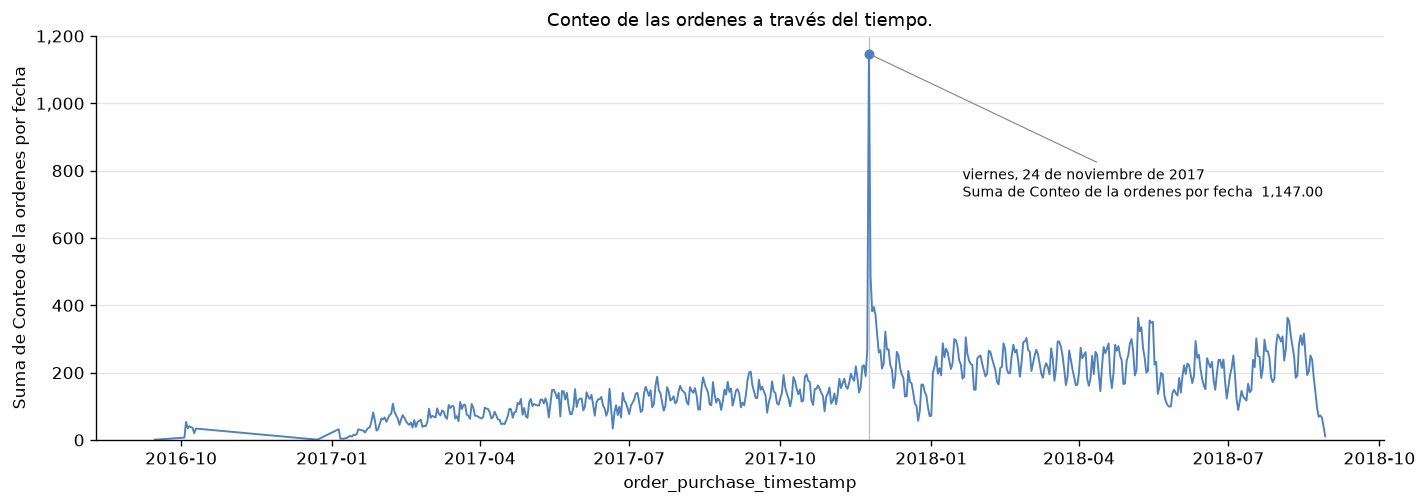

In [19]:
fig, ax = plt.subplots(figsize=(12, 4.3))
ax.plot(serie.index, serie["conteo"], color="#4F81BD", lw=1.15)
pico = pd.Timestamp("2017-11-24")
valor_pico = float(serie.loc[pico, "conteo"])
ax.plot(pico, valor_pico, "o", color="#4F81BD", ms=5, zorder=3)
ax.axvline(pico, color="#BFBFBF", lw=0.8, zorder=0)
ax.annotate(
    f"viernes, 24 de noviembre de 2017\nSuma de Conteo de la ordenes por fecha  {valor_pico:,.2f}",
    xy=(pico, valor_pico),
    xytext=(pd.Timestamp("2018-01-20"), 760),
    fontsize=8.5,
    arrowprops=dict(arrowstyle="-", color="#888888", lw=0.7),
    va="center",
)
ax.set_ylim(0, 1200)
ax.set_yticks([0, 200, 400, 600, 800, 1000, 1200])
ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, _pos: f"{valor:,.0f}"))
ax.set_title("Conteo de las ordenes a través del tiempo.")
ax.set_xlabel("order_purchase_timestamp")
ax.set_ylabel("Suma de Conteo de la ordenes por fecha")
ax.yaxis.grid(True, color="#E6E6E6")
ax.set_axisbelow(True)
fig.tight_layout()
display(fig)
plt.close(fig)


### Tiempo estimado y tiempo real, ponderados por el monto pagado

La línea clara es el tiempo real de entrega. La línea oscura es el tiempo que se le prometió al cliente. Durante casi todo el periodo la promesa está por encima de la entrega observada: las órdenes entregadas suelen llegar antes de la fecha estimada.

El desplome de las dos series después de julio de 2018 no se lee como una mejora súbita de la logística. La base solo conserva órdenes ya entregadas, y el extracto termina a finales de agosto de 2018. Las compras recientes que todavía no habían llegado no entran en el promedio, así que al final solo quedan las entregas cortas.


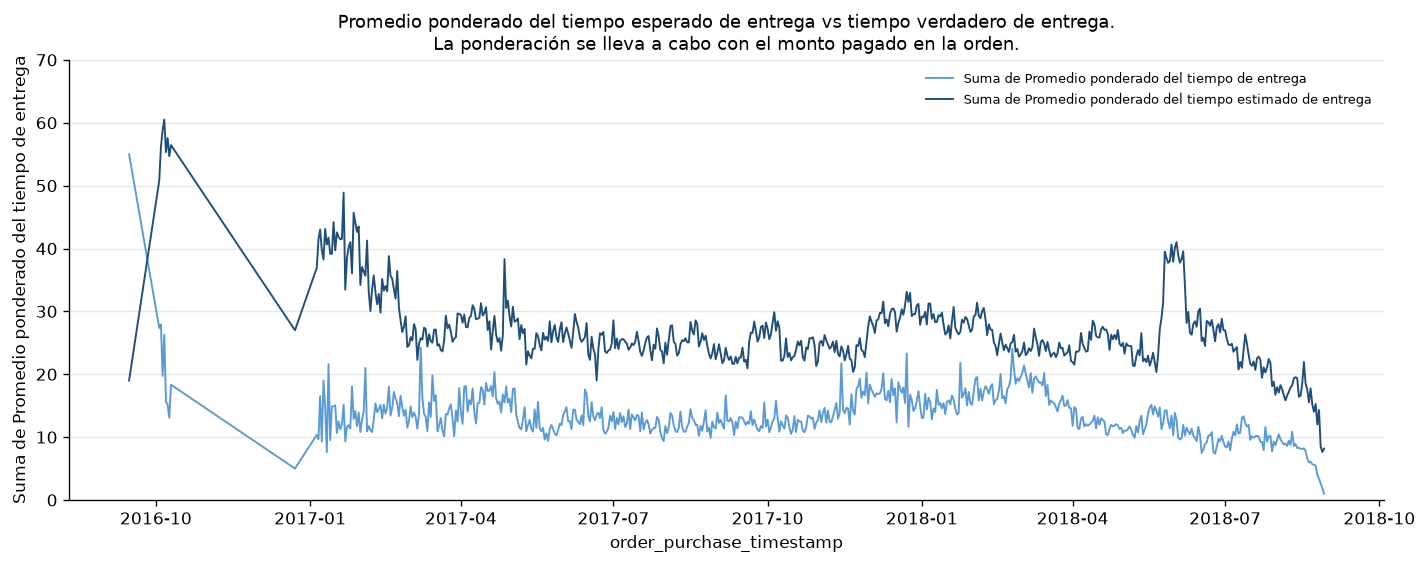

Máximo del tiempo estimado ponderado entre mayo y junio de 2018: 41.0 días el 2018-06-02
Último día de la serie 2018-08-29 | real 1.0 | estimado 8.2


In [20]:
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(
    serie.index,
    serie["promedio_ponderado_entrega"],
    color="#5B9BD5",
    lw=1.15,
    label="Suma de Promedio ponderado del tiempo de entrega",
)
ax.plot(
    serie.index,
    serie["promedio_ponderado_estimado"],
    color="#1F4E79",
    lw=1.15,
    label="Suma de Promedio ponderado del tiempo estimado de entrega",
)
ax.set_ylim(0, 70)
ax.set_yticks(range(0, 71, 10))
ax.set_title(
    "Promedio ponderado del tiempo esperado de entrega vs tiempo verdadero de entrega.\n"
    "La ponderación se lleva a cabo con el monto pagado en la orden."
)
ax.set_xlabel("order_purchase_timestamp")
ax.set_ylabel("Suma de Promedio ponderado del tiempo de entrega")
ax.legend(frameon=False, loc="upper right", fontsize=8)
ax.yaxis.grid(True, color="#E6E6E6")
ax.set_axisbelow(True)
fig.tight_layout()
display(fig)
plt.close(fig)

recorte_2018 = serie.loc["2018-05-01":"2018-06-30", "promedio_ponderado_estimado"]
print(
    "Máximo del tiempo estimado ponderado entre mayo y junio de 2018:",
    f"{recorte_2018.max():.1f} días el {recorte_2018.idxmax().date()}",
)
print(
    "Último día de la serie",
    serie.index.max().date(),
    f"| real {serie['promedio_ponderado_entrega'].iloc[-1]:.1f}",
    f"| estimado {serie['promedio_ponderado_estimado'].iloc[-1]:.1f}",
)


## 7. Gráficas de conciliación y de medios de pago

La población de las donas de pago y de plazos no es todo el catálogo. Es el subconjunto cuya diferencia redondeada es distinta de cero: 318 órdenes. Esas órdenes pueden tener más de un registro en la tabla de pagos.

El tablero cuenta órdenes distintas por tipo de pago y, por separado, órdenes distintas por plazo. Una orden con tarjeta y vale entra en los dos tipos; una orden con dos plazos distintos entra en los dos plazos. Por eso los gajos suman 326 y 328, no 318. Los porcentajes del tablero usan esa suma de gajos como denominador, y así se calculan aquí.

El plazo reproduce los cortes del tablero: 1 cuota («Un unico pago»), 2 cuotas («Dos pagos»), 3 a 5 («De 2 a 5 pagos»), 6 a 10, 11 a 15, 16 a 20 y 21 a 24. La etiqueta «De 2 a 5 pagos» del tablero no incluye las 2 cuotas, que ya tienen su propio gajo.


Base de la dona de estatus (diferencia no calculable): 776
De ellas, sin costo: 775 | sin pago y con costo: 1


,ordenes
bandera,
Sin diferencias,98347
Con diferencias,1094


,ordenes
bandera_detalle,
Con valores faltantes,776
Con diferencias,318


,ordenes_sin_diferencia_calculable
order_status,
canceled,164
created,5
delivered,1
invoiced,2
shipped,1
unavailable,603


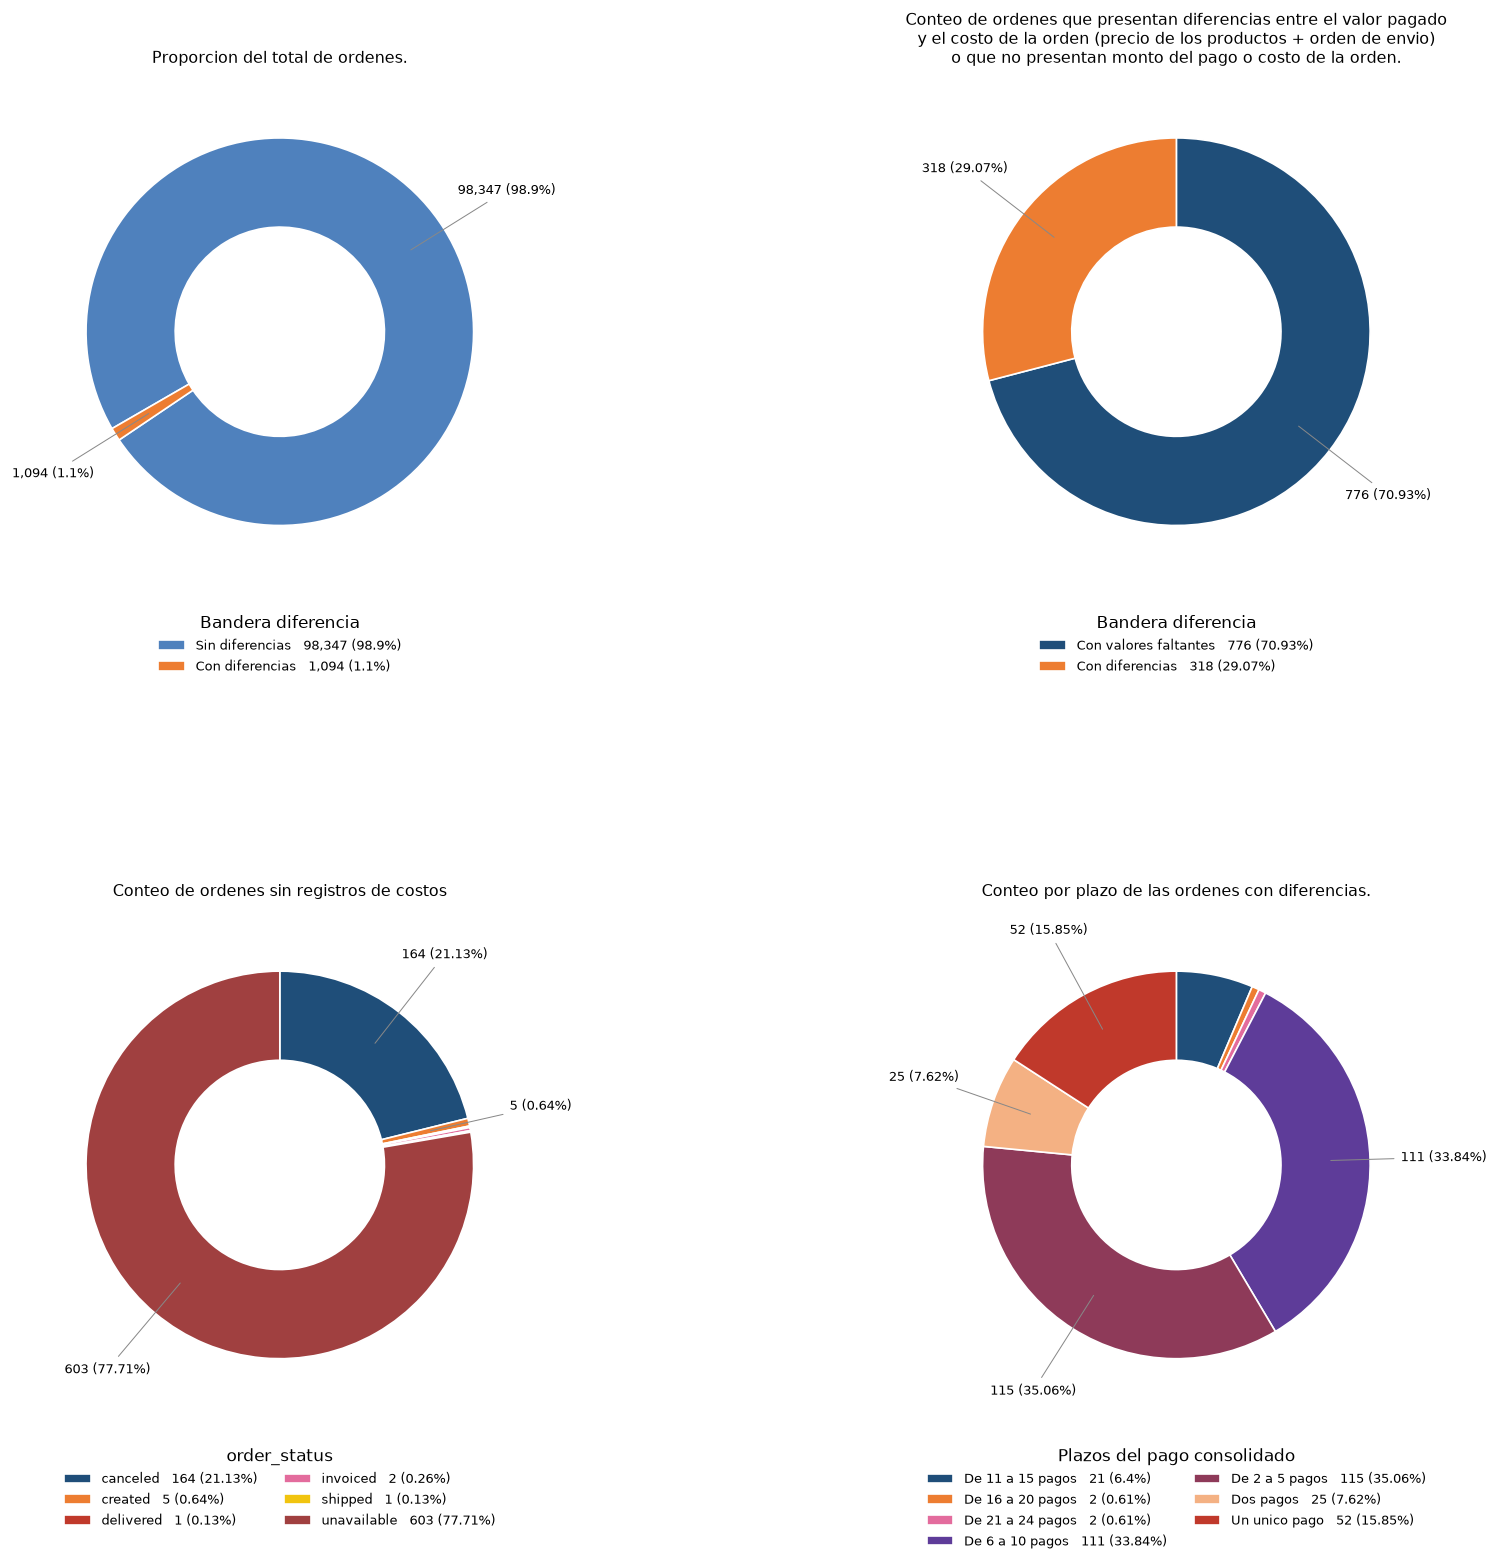

,ordenes_distintas
plazo,
De 11 a 15 pagos,21
De 16 a 20 pagos,2
De 21 a 24 pagos,2
De 6 a 10 pagos,111
De 2 a 5 pagos,115
Dos pagos,25
Un unico pago,52


Órdenes con diferencia redondeada: 318 | gajos de plazo (una orden puede caer en dos): 328


In [21]:
def formato_conteo(valor, total):
    porcentaje = 100.0 * valor / total
    texto = f"{porcentaje:.2f}".rstrip("0").rstrip(".")
    return f"{valor:,.0f} ({texto}%)"


def grafica_dona(ax, conteos, colores, titulo, titulo_leyenda, min_pct=8.0, startangle=90, leyenda="abajo"):
    etiquetas = list(conteos.index)
    valores = np.asarray([conteos[etiqueta] for etiqueta in etiquetas], dtype=float)
    total = float(valores.sum())
    wedges, _ = ax.pie(
        valores,
        colors=[colores.get(etiqueta, "#999999") for etiqueta in etiquetas],
        startangle=startangle,
        counterclock=False,
        wedgeprops=dict(width=0.46, edgecolor="white", linewidth=1),
    )
    for wedge, valor in zip(wedges, valores):
        if 100 * valor / total < min_pct:
            continue
        angulo = np.deg2rad((wedge.theta1 + wedge.theta2) / 2.0)
        x = float(np.cos(angulo))
        y = float(np.sin(angulo))
        ax.annotate(
            formato_conteo(valor, total),
            xy=(0.78 * x, 0.78 * y),
            xytext=(1.38 * x, 1.38 * y),
            ha="center",
            va="center",
            fontsize=8,
            arrowprops=dict(arrowstyle="-", color="#888888", lw=0.6),
            annotation_clip=False,
        )
    if leyenda == "abajo":
        columnas = 1 if len(etiquetas) <= 2 else 2
        ax.legend(
            wedges,
            [f"{etiqueta}   {formato_conteo(valor, total)}" for etiqueta, valor in zip(etiquetas, valores)],
            title=titulo_leyenda,
            loc="upper center",
            bbox_to_anchor=(0.5, -0.06),
            ncol=columnas,
            frameon=False,
            fontsize=8,
        )
    else:
        ax.legend(
            wedges,
            [f"{etiqueta}   {formato_conteo(valor, total)}" for etiqueta, valor in zip(etiquetas, valores)],
            title=titulo_leyenda,
            loc="center left",
            bbox_to_anchor=(1.02, 0.5),
            frameon=False,
            fontsize=8,
        )
    ax.set_title(titulo, loc="center", fontsize=9.5, pad=16)


conteo_bandera = (
    comparacion_ordenes["bandera"]
    .value_counts()
    .reindex(["Sin diferencias", "Con diferencias"])
)
excepciones = comparacion_ordenes.loc[comparacion_ordenes["bandera"] == "Con diferencias"]
conteo_detalle = (
    excepciones["bandera_detalle"]
    .value_counts()
    .reindex(["Con valores faltantes", "Con diferencias"])
)
faltantes = comparacion_ordenes.loc[comparacion_ordenes["diferencia"].isna()]
orden_status = ["canceled", "created", "delivered", "invoiced", "shipped", "unavailable"]
conteo_status = faltantes["order_status"].value_counts().reindex(orden_status).fillna(0).astype(int)

colores_bandera = {"Sin diferencias": "#4F81BD", "Con diferencias": "#ED7D31"}
colores_detalle = {"Con valores faltantes": "#1F4E79", "Con diferencias": "#ED7D31"}
colores_status = {
    "canceled": "#1F4E79",
    "created": "#ED7D31",
    "delivered": "#C0392B",
    "invoiced": "#E36C9D",
    "shipped": "#F1C40F",
    "unavailable": "#A04040",
}

fig, axes = plt.subplots(2, 2, figsize=(14.8, 12.2))
grafica_dona(
    axes[0, 0], conteo_bandera, colores_bandera,
    "Proporcion del total de ordenes.", "Bandera diferencia",
    min_pct=0.5, startangle=210,
)
grafica_dona(
    axes[0, 1], conteo_detalle, colores_detalle,
    "Conteo de ordenes que presentan diferencias entre el valor pagado\n"
    "y el costo de la orden (precio de los productos + orden de envio)\n"
    "o que no presentan monto del pago o costo de la orden.",
    "Bandera diferencia", min_pct=0.5,
)
grafica_dona(
    axes[1, 0], conteo_status, colores_status,
    "Conteo de ordenes sin registros de costos", "order_status", min_pct=0.4,
)
print("Base de la dona de estatus (diferencia no calculable):", int(conteo_status.sum()))
print("De ellas, sin costo:", int(comparacion_ordenes["costo"].isna().sum()),
      "| sin pago y con costo:", int((comparacion_ordenes["pago_realizado"].isna() & comparacion_ordenes["costo"].notna()).sum()))
display(conteo_bandera.to_frame("ordenes"))
display(conteo_detalle.to_frame("ordenes"))
display(conteo_status.to_frame("ordenes_sin_diferencia_calculable"))


def clasificar_plazo(cuotas):
    cuotas = int(cuotas)
    if cuotas == 1:
        return "Un unico pago"
    if cuotas == 2:
        return "Dos pagos"
    if 3 <= cuotas <= 5:
        return "De 2 a 5 pagos"
    if 6 <= cuotas <= 10:
        return "De 6 a 10 pagos"
    if 11 <= cuotas <= 15:
        return "De 11 a 15 pagos"
    if 16 <= cuotas <= 20:
        return "De 16 a 20 pagos"
    if 21 <= cuotas <= 24:
        return "De 21 a 24 pagos"
    return "Otro"


orden_plazo = [
    "De 11 a 15 pagos",
    "De 16 a 20 pagos",
    "De 21 a 24 pagos",
    "De 6 a 10 pagos",
    "De 2 a 5 pagos",
    "Dos pagos",
    "Un unico pago",
]
colores_plazo = {
    "De 11 a 15 pagos": "#1F4E79",
    "De 16 a 20 pagos": "#ED7D31",
    "De 21 a 24 pagos": "#E36C9D",
    "De 6 a 10 pagos": "#5E3C99",
    "De 2 a 5 pagos": "#8E3A59",
    "Dos pagos": "#F4B183",
    "Un unico pago": "#C0392B",
}

con_diferencia = comparacion_ordenes.loc[
    comparacion_ordenes["diferencia"].notna() & comparacion_ordenes["diferencia"].ne(0),
    ["order_id", "fecha_compra", "order_status", "diferencia"],
]
pagos_dif = pagos.merge(con_diferencia[["order_id", "fecha_compra"]], on="order_id", how="inner")
assert pagos_dif["payment_installments"].notna().all()
pagos_dif["plazo"] = pagos_dif["payment_installments"].map(clasificar_plazo)
conteo_plazos = pagos_dif.groupby("plazo")["order_id"].nunique().reindex(orden_plazo)
grafica_dona(
    axes[1, 1], conteo_plazos, colores_plazo,
    "Conteo por plazo de las ordenes con diferencias.",
    "Plazos del pago consolidado", min_pct=7,
)
fig.subplots_adjust(left=0.04, right=0.98, top=0.94, bottom=0.04, hspace=0.72, wspace=0.16)
display(fig)
plt.close(fig)
display(conteo_plazos.to_frame("ordenes_distintas"))
print(
    "Órdenes con diferencia redondeada:",
    con_diferencia["order_id"].nunique(),
    "| gajos de plazo (una orden puede caer en dos):",
    int(conteo_plazos.sum()),
)


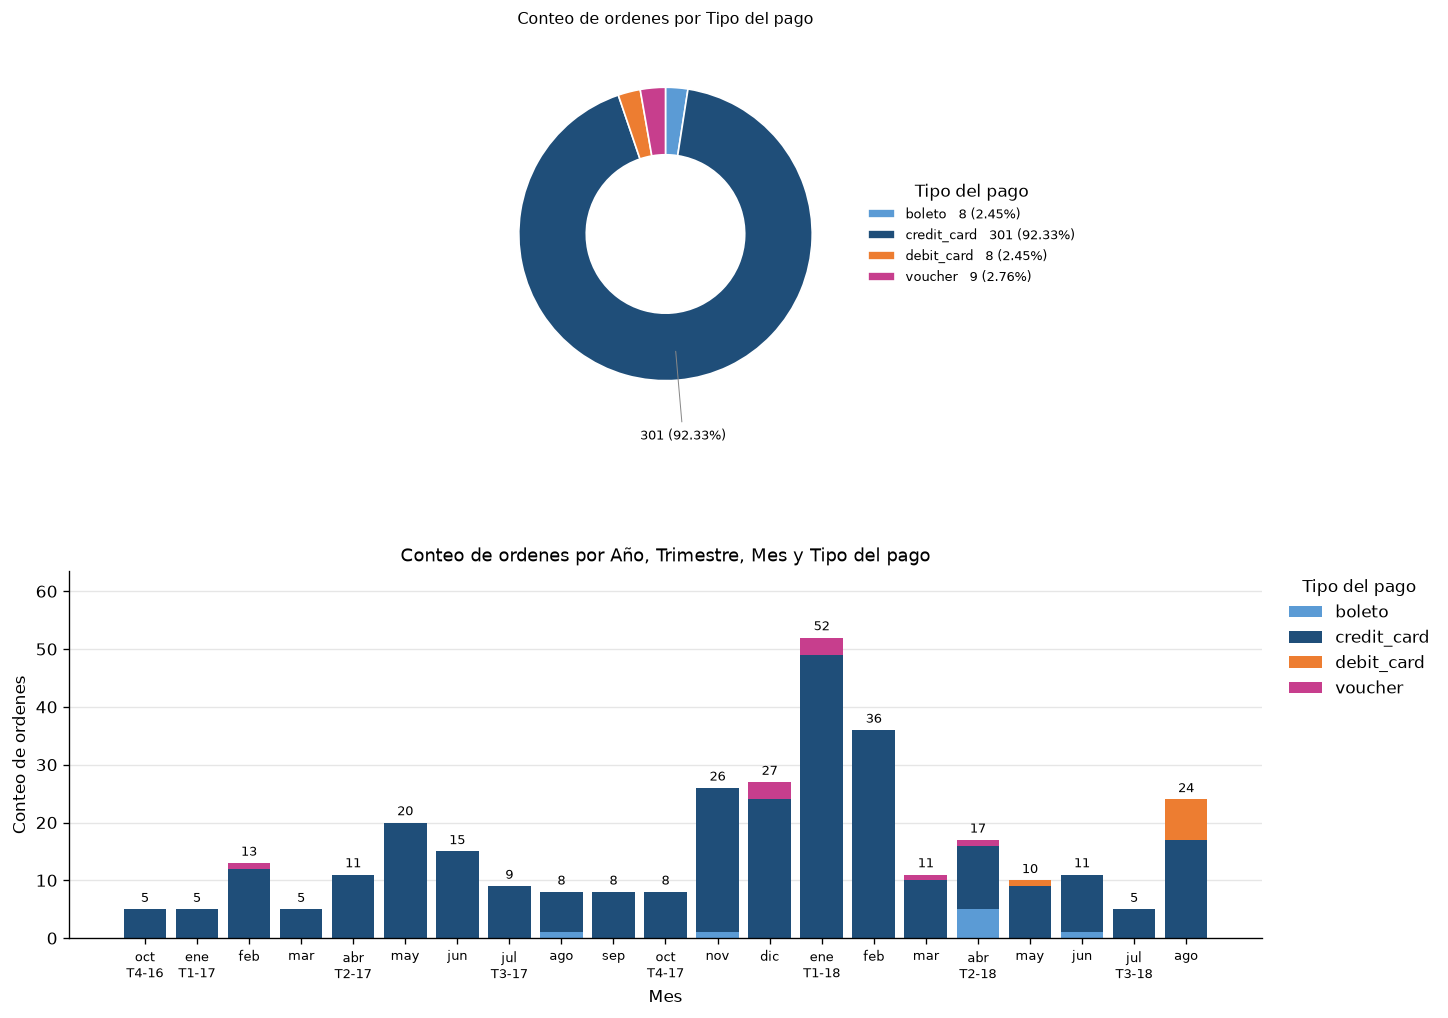

,ordenes_distintas
payment_type,
boleto,8
credit_card,301
debit_card,8
voucher,9


payment_type,boleto,credit_card,debit_card,voucher,total
mes,,,,,
2016-10,0,5,0,0,5
2017-01,0,5,0,0,5
2017-02,0,12,0,1,13
2017-03,0,5,0,0,5
2017-04,0,11,0,0,11
2017-05,0,20,0,0,20
2017-06,0,15,0,0,15
2017-07,0,9,0,0,9
2017-08,1,7,0,0,8


Gajos de tipo de pago: 326 | órdenes distintas: 318


In [22]:
orden_tipos = ["boleto", "credit_card", "debit_card", "voucher"]
colores_tipo = {
    "boleto": "#5B9BD5",
    "credit_card": "#1F4E79",
    "debit_card": "#ED7D31",
    "voucher": "#C73E8D",
}
tipo_orden = pagos_dif.drop_duplicates(["order_id", "payment_type"]).copy()
conteo_tipo = (
    tipo_orden.groupby("payment_type")["order_id"].nunique()
    .reindex(orden_tipos)
    .fillna(0)
    .astype(int)
)
tipo_orden["mes"] = tipo_orden["fecha_compra"].dt.to_period("M")
mensual = (
    tipo_orden.groupby(["mes", "payment_type"])["order_id"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=orden_tipos, fill_value=0)
    .sort_index()
)

fig = plt.figure(figsize=(13.8, 8.6))
ax_dona = fig.add_subplot(2, 1, 1)
ax_barras = fig.add_subplot(2, 1, 2)
grafica_dona(
    ax_dona, conteo_tipo, colores_tipo,
    "Conteo de ordenes por Tipo del pago", "Tipo del pago",
    min_pct=10, leyenda="derecha",
)

x = np.arange(len(mensual))
fondo = np.zeros(len(mensual))
for tipo in orden_tipos:
    valores = mensual[tipo].to_numpy(dtype=float)
    ax_barras.bar(x, valores, bottom=fondo, width=0.82, color=colores_tipo[tipo], label=tipo)
    fondo = fondo + valores
for posicion, total in enumerate(fondo):
    ax_barras.text(posicion, total + 0.7, f"{int(total)}", ha="center", va="bottom", fontsize=8)

etiquetas = []
trimestre_previo = None
for periodo in mensual.index:
    trimestre = f"T{(periodo.month - 1) // 3 + 1} {periodo.year}"
    mes = MESES[periodo.month - 1]
    if trimestre != trimestre_previo:
        etiquetas.append(f"{mes}\nT{(periodo.month - 1) // 3 + 1}-{str(periodo.year)[2:]}")
        trimestre_previo = trimestre
    else:
        etiquetas.append(mes)
ax_barras.set_xticks(x)
ax_barras.set_xticklabels(etiquetas, fontsize=8)
ax_barras.set_ylim(0, max(fondo) * 1.22)
ax_barras.set_ylabel("Conteo de ordenes")
ax_barras.set_xlabel("Mes")
ax_barras.set_title("Conteo de ordenes por Año, Trimestre, Mes y Tipo del pago")
ax_barras.legend(
    title="Tipo del pago", frameon=False,
    loc="upper left", bbox_to_anchor=(1.01, 1.02),
)
ax_barras.yaxis.grid(True, color="#E6E6E6")
ax_barras.set_axisbelow(True)
fig.subplots_adjust(left=0.06, right=0.78, top=0.94, bottom=0.08, hspace=0.42)
display(fig)
plt.close(fig)

display(conteo_tipo.to_frame("ordenes_distintas"))
display(mensual.assign(total=mensual.sum(axis=1)))
print(
    "Gajos de tipo de pago:",
    int(conteo_tipo.sum()),
    "| órdenes distintas:",
    int(tipo_orden["order_id"].nunique()),
)


## 8. Productos y categorías

Se unen artículos, ficha de producto y traducción al inglés. El script de R documenta 1,603 artículos sin categoría; el precio sí está en todos los artículos de la unión.

Las categorías en inglés se agrupan con las mismas listas del script de R, incluidos los nombres mal escritos que trae el catálogo (`fashio_female_clothing`, `home_confort`, `costruction_tools_garden`). Lo que no entra en ninguna lista queda en «Otros». Esa lista no incluye `baby`, así que los artículos de bebé caen ahí junto con los que no tienen traducción.


Artículos o productos sin categoría: 1603
Registros de la unión sin precio: 0


,categoria_general,articulos
0,Hogar y mobiliario,29513
1,Tecnología y electrónica,18954
2,Entretenimiento y recreación,17851
3,Belleza y cuidado personal,13128
4,Moda y accesorios,9725
5,Construcción y jardín,7016
6,Automotriz e industria,5015
7,Otros,4692
8,Libros y papelería,3397
9,Mascotas y flores,1980


El script de R no asigna la categoría baby a ningún grupo. Otros la reúne con los artículos sin traducción.


,articulos
product_category_name_english,
baby,3065
NaN,1627


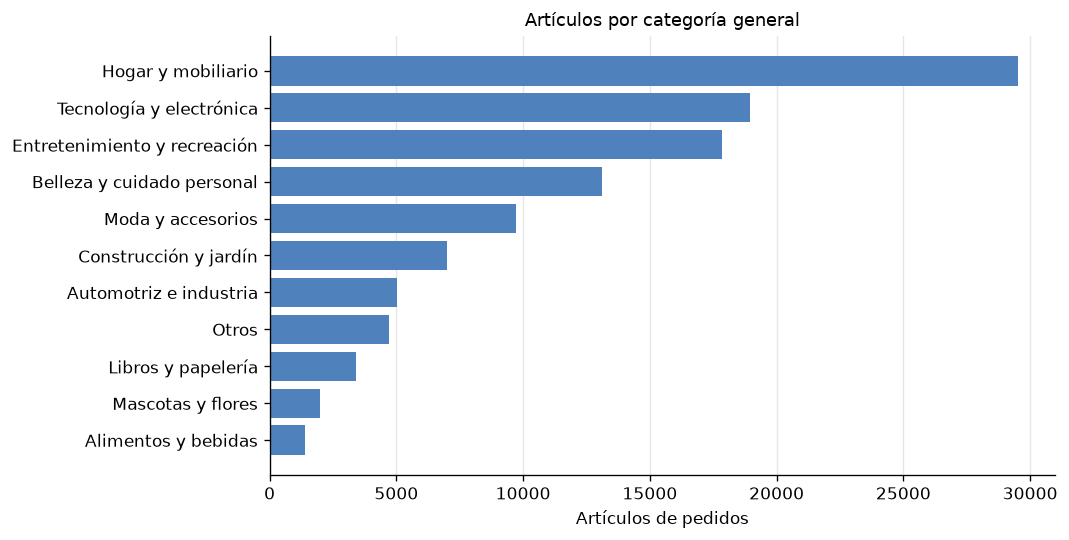

In [23]:
revision_productos = articulos.merge(productos, on="product_id", how="outer")
print("Artículos o productos sin categoría:", int(revision_productos["product_category_name"].isna().sum()))
print("Registros de la unión sin precio:", int(revision_productos["price"].isna().sum()))

GRUPOS = {
    "Tecnología y electrónica": [
        "audio", "computers", "computers_accessories", "consoles_games", "electronics",
        "fixed_telephony", "telephony", "tablets_printing_image", "small_appliances",
        "small_appliances_home_oven_and_coffee", "home_appliances", "home_appliances_2",
    ],
    "Hogar y mobiliario": [
        "bed_bath_table", "furniture_bedroom", "furniture_decor", "furniture_living_room",
        "furniture_mattress_and_upholstery", "home_comfort_2", "home_confort", "housewares",
        "kitchen_dining_laundry_garden_furniture", "la_cuisine", "office_furniture",
    ],
    "Moda y accesorios": [
        "fashio_female_clothing", "fashion_bags_accessories", "fashion_childrens_clothes",
        "fashion_male_clothing", "fashion_shoes", "fashion_sport", "fashion_underwear_beach",
        "watches_gifts", "luggage_accessories",
    ],
    "Belleza y cuidado personal": ["health_beauty", "perfumery", "diapers_and_hygiene"],
    "Construcción y jardín": [
        "construction_tools_construction", "construction_tools_lights", "construction_tools_safety",
        "costruction_tools_garden", "costruction_tools_tools", "garden_tools",
        "home_construction", "air_conditioning",
    ],
    "Entretenimiento y recreación": [
        "sports_leisure", "toys", "cool_stuff", "christmas_supplies", "party_supplies",
        "art", "arts_and_craftmanship", "cine_photo", "cds_dvds_musicals", "dvds_blu_ray",
        "music", "musical_instruments",
    ],
    "Libros y papelería": [
        "books_general_interest", "books_imported", "books_technical", "stationery",
    ],
    "Alimentos y bebidas": ["agro_industry_and_commerce", "drinks", "food", "food_drink"],
    "Automotriz e industria": [
        "auto", "industry_commerce_and_business", "market_place",
        "signaling_and_security", "security_and_services",
    ],
    "Mascotas y flores": ["pet_shop", "flowers"],
}
mapa_categoria = {
    categoria: grupo
    for grupo, categorias in GRUPOS.items()
    for categoria in categorias
}

productos_por_orden = (
    articulos.merge(productos, on="product_id", how="left")
    .merge(traduccion, on="product_category_name", how="left")
)
productos_por_orden["categoria_general"] = (
    productos_por_orden["product_category_name_english"].map(mapa_categoria).fillna("Otros")
)
conteo_categorias = (
    productos_por_orden["categoria_general"].value_counts()
    .rename_axis("categoria_general")
    .rename("articulos")
    .reset_index()
)
display(conteo_categorias)
otros = (
    productos_por_orden.loc[
        productos_por_orden["categoria_general"] == "Otros",
        "product_category_name_english",
    ]
    .value_counts(dropna=False)
    .rename_axis("product_category_name_english")
    .rename("articulos")
)
print("El script de R no asigna la categoría baby a ningún grupo. Otros la reúne con los artículos sin traducción.")
display(otros.to_frame())

fig, ax = plt.subplots(figsize=(9, 4.6))
ordenado = conteo_categorias.sort_values("articulos")
ax.barh(ordenado["categoria_general"], ordenado["articulos"], color="#4F81BD")
ax.set_xlabel("Artículos de pedidos")
ax.set_title("Artículos por categoría general")
ax.xaxis.grid(True, color="#E6E6E6")
ax.set_axisbelow(True)
fig.tight_layout()
display(fig)
plt.close(fig)


## 9. Región, peso del envío y distancia lineal

La región sale del estado del cliente, con la misma clasificación del script de R. El conteo es de artículos integrados, no de órdenes: una orden con tres productos suma tres.

El código postal se rellena a cinco dígitos en los dos lados del cruce. El script de R rellena el prefijo del cliente y del vendedor; si el catálogo geográfico se lee como número, un prefijo como `01234` no coincidiría con `1234`. Aquí los dos lados quedan en el mismo formato, que es lo que busca ese relleno.

La distancia es la del script de R: la raíz de la suma de cuadrados de las diferencias de latitud y de longitud. Está en grados, no en kilómetros, y no es una ruta de reparto. De cada prefijo postal se conserva la primera coordenada del archivo, igual que `distinct(..., .keep_all = TRUE)`.


Artículos sin estado del cliente: 0


,region,articulos,porcentaje
0,Sudeste,77413,68.719929
1,Sur,16151,14.337328
2,Nordeste,10409,9.240124
3,Centro-Oeste,6613,5.870395
4,Norte,2064,1.832224


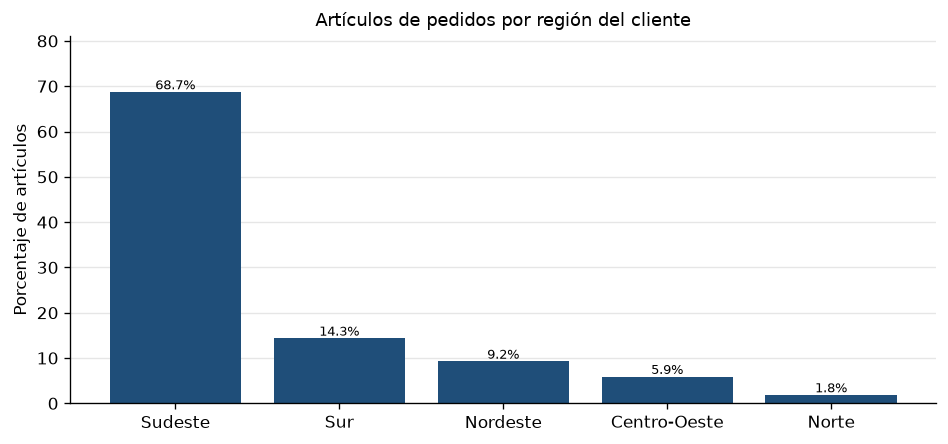

Correlación entre peso medio y flete medio del producto: 0.654
Productos sin peso o sin flete: 2


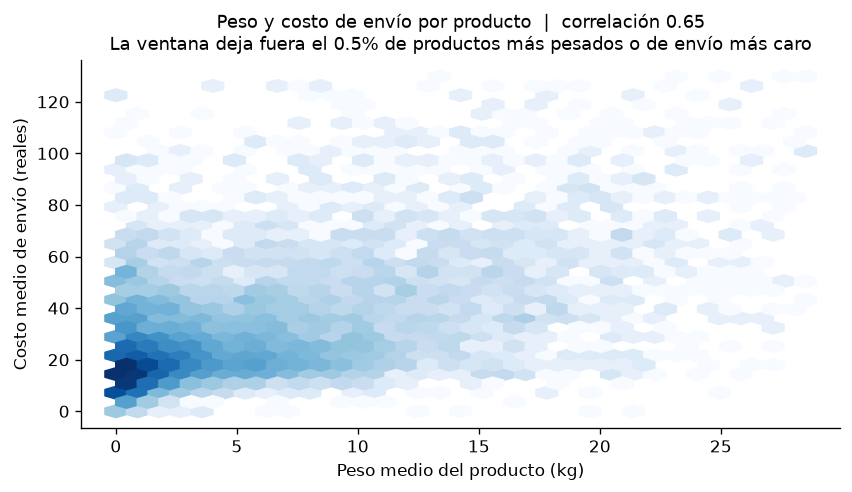

Artículos con coordenada de cliente y de vendedor: 99.5%


,flete,peso,distancia
count,98175.000,98159.000,98175.000
mean,20.230,2101.308,5.587
std,16.052,3750.498,5.430
min,0.000,0.000,0.000
25%,13.370,300.000,1.744
50%,16.350,700.000,4.081
75%,21.190,1813.000,7.427
max,409.680,40425.000,80.026


Correlación distancia–flete: 0.39 | distancia–peso: -0.007


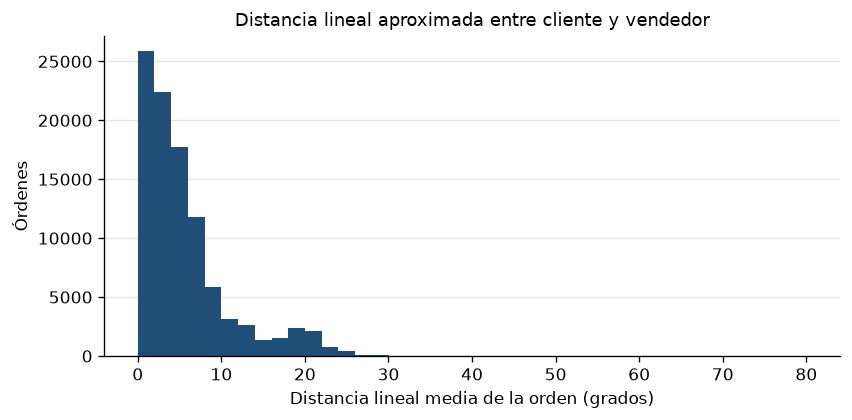

In [24]:
def zip5(serie):
    return serie.astype("string").str.replace(r"\.0$", "", regex=True).str.zfill(5)


integrada = (
    productos_por_orden
    .merge(ordenes, on="order_id", how="left")
    .merge(clientes, on="customer_id", how="left")
)
print("Artículos sin estado del cliente:", int(integrada["customer_state"].isna().sum()))

regiones = {
    "Norte": ["AC", "AP", "AM", "PA", "RO", "RR", "TO"],
    "Nordeste": ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"],
    "Centro-Oeste": ["DF", "GO", "MT", "MS"],
    "Sudeste": ["ES", "MG", "RJ", "SP"],
    "Sur": ["PR", "RS", "SC"],
}
mapa_region = {estado: region for region, estados in regiones.items() for estado in estados}
integrada["region"] = integrada["customer_state"].map(mapa_region).fillna("Sin clasificación")
conteo_region = (
    integrada["region"].value_counts()
    .rename_axis("region")
    .rename("articulos")
    .reset_index()
)
conteo_region["porcentaje"] = conteo_region["articulos"] / conteo_region["articulos"].sum() * 100
display(conteo_region)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(conteo_region["region"], conteo_region["porcentaje"], color="#1F4E79")
for region, porcentaje in zip(conteo_region["region"], conteo_region["porcentaje"]):
    ax.text(region, porcentaje + 0.6, f"{porcentaje:.1f}%", ha="center", fontsize=8)
ax.set_ylim(0, conteo_region["porcentaje"].max() * 1.18)
ax.set_ylabel("Porcentaje de artículos")
ax.set_title("Artículos de pedidos por región del cliente")
ax.yaxis.grid(True, color="#E6E6E6")
ax.set_axisbelow(True)
fig.tight_layout()
display(fig)
plt.close(fig)

relacion_peso = (
    integrada.groupby("product_id", as_index=False)
    .agg(flete=("freight_value", "mean"), peso=("product_weight_g", "mean"))
)
correlacion_peso = relacion_peso["peso"].corr(relacion_peso["flete"])
print(f"Correlación entre peso medio y flete medio del producto: {correlacion_peso:.3f}")
print(f"Productos sin peso o sin flete: {int(relacion_peso[['peso', 'flete']].isna().any(axis=1).sum())}")

fig, ax = plt.subplots(figsize=(7.2, 4.2))
completos = relacion_peso.dropna()
peso_kg = completos["peso"] / 1000
flete = completos["flete"]
ventana = (peso_kg <= peso_kg.quantile(0.995)) & (flete <= flete.quantile(0.995))
ax.hexbin(peso_kg[ventana], flete[ventana], gridsize=32, cmap="Blues", mincnt=1, bins="log")
ax.set_xlabel("Peso medio del producto (kg)")
ax.set_ylabel("Costo medio de envío (reales)")
ax.set_title(
    f"Peso y costo de envío por producto  |  correlación {correlacion_peso:.2f}\n"
    "La ventana deja fuera el 0.5% de productos más pesados o de envío más caro"
)
fig.tight_layout()
display(fig)
plt.close(fig)

geo = geolocalizacion.copy()
geo["geolocation_zip_code_prefix"] = zip5(geo["geolocation_zip_code_prefix"])
geo = geo.drop_duplicates("geolocation_zip_code_prefix", keep="first")
coordenadas_cliente = geo.rename(columns={
    "geolocation_zip_code_prefix": "customer_zip_code_prefix",
    "geolocation_lat": "lat_cliente",
    "geolocation_lng": "lng_cliente",
})
coordenadas_vendedor = geo.rename(columns={
    "geolocation_zip_code_prefix": "seller_zip_code_prefix",
    "geolocation_lat": "lat_vendedor",
    "geolocation_lng": "lng_vendedor",
})

con_ubicacion = integrada.copy()
con_ubicacion["customer_zip_code_prefix"] = zip5(con_ubicacion["customer_zip_code_prefix"])
con_ubicacion = con_ubicacion.merge(coordenadas_cliente, on="customer_zip_code_prefix", how="left")
con_ubicacion = con_ubicacion.merge(
    vendedores[["seller_id", "seller_zip_code_prefix"]],
    on="seller_id",
    how="left",
)
con_ubicacion["seller_zip_code_prefix"] = zip5(con_ubicacion["seller_zip_code_prefix"])
con_ubicacion = con_ubicacion.merge(coordenadas_vendedor, on="seller_zip_code_prefix", how="left")
con_ubicacion["distancia_lineal"] = np.sqrt(
    (con_ubicacion["lat_cliente"] - con_ubicacion["lat_vendedor"]) ** 2
    + (con_ubicacion["lng_cliente"] - con_ubicacion["lng_vendedor"]) ** 2
)

cobertura = con_ubicacion["distancia_lineal"].notna().mean() * 100
print(f"Artículos con coordenada de cliente y de vendedor: {cobertura:.1f}%")

distancia_pedido = (
    con_ubicacion.loc[con_ubicacion["distancia_lineal"].notna()]
    .groupby("order_id", as_index=False)
    .agg(
        flete=("freight_value", "mean"),
        peso=("product_weight_g", "mean"),
        distancia=("distancia_lineal", "mean"),
    )
)
display(distancia_pedido[["flete", "peso", "distancia"]].describe().round(3))
print(
    "Correlación distancia–flete:",
    round(distancia_pedido["distancia"].corr(distancia_pedido["flete"]), 3),
    "| distancia–peso:",
    round(distancia_pedido["distancia"].corr(distancia_pedido["peso"]), 3),
)

fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.hist(distancia_pedido["distancia"], bins=40, color="#1F4E79")
ax.set_xlabel("Distancia lineal media de la orden (grados)")
ax.set_ylabel("Órdenes")
ax.set_title("Distancia lineal aproximada entre cliente y vendedor")
ax.yaxis.grid(True, color="#E6E6E6")
ax.set_axisbelow(True)
fig.tight_layout()
display(fig)
plt.close(fig)


## 10. Validación

Las comprobaciones fijan las cifras leídas en las gráficas del tablero y las relaciones que el script de R deja escritas. Si alguna no se cumple, la celda se detiene.


In [25]:
comprobaciones = []


def esperar(nombre, obtenido, esperado):
    comprobaciones.append((nombre, esperado, obtenido, obtenido == esperado))
    if obtenido != esperado:
        raise AssertionError(f"{nombre}: esperado {esperado}, obtenido {obtenido}")


esperar("ordenes", len(ordenes), 99441)
esperar("order_id duplicados", int(ordenes["order_id"].duplicated().sum()), 0)
esperar("customer_id duplicados", int(ordenes["customer_id"].duplicated().sum()), 0)
esperar(
    "entregadas el 24 nov 2017",
    int(serie.loc[pd.Timestamp("2017-11-24"), "conteo"]),
    1147,
)
esperar("conteo de la serie igual a entregadas", int(serie["conteo"].sum()), 96478)
esperar("sin diferencias", int(conteo_bandera["Sin diferencias"]), 98347)
esperar("con diferencias o faltantes", int(conteo_bandera["Con diferencias"]), 1094)
esperar("diferencia redondeada distinta de cero", int(conteo_detalle["Con diferencias"]), 318)
esperar("valores faltantes", int(conteo_detalle["Con valores faltantes"]), 776)
esperar("sin costo", int(comparacion["costo"].isna().sum()), 775)
esperar("sin pago", int(comparacion["pago_realizado"].isna().sum()), 1)
esperar("unavailable entre faltantes", int(conteo_status["unavailable"]), 603)
esperar("canceled entre faltantes", int(conteo_status["canceled"]), 164)
esperar("created entre faltantes", int(conteo_status["created"]), 5)
esperar("invoiced entre faltantes", int(conteo_status["invoiced"]), 2)
esperar("shipped entre faltantes", int(conteo_status["shipped"]), 1)
esperar("delivered entre faltantes", int(conteo_status["delivered"]), 1)
esperar("credit_card en ordenes con diferencia", int(conteo_tipo["credit_card"]), 301)
esperar("boleto en ordenes con diferencia", int(conteo_tipo["boleto"]), 8)
esperar("debit_card en ordenes con diferencia", int(conteo_tipo["debit_card"]), 8)
esperar("voucher en ordenes con diferencia", int(conteo_tipo["voucher"]), 9)
esperar("gajos de tipo de pago", int(conteo_tipo.sum()), 326)
esperar("Un unico pago", int(conteo_plazos["Un unico pago"]), 52)
esperar("Dos pagos", int(conteo_plazos["Dos pagos"]), 25)
esperar("De 2 a 5 pagos", int(conteo_plazos["De 2 a 5 pagos"]), 115)
esperar("De 6 a 10 pagos", int(conteo_plazos["De 6 a 10 pagos"]), 111)
esperar("De 11 a 15 pagos", int(conteo_plazos["De 11 a 15 pagos"]), 21)
esperar("De 16 a 20 pagos", int(conteo_plazos["De 16 a 20 pagos"]), 2)
esperar("De 21 a 24 pagos", int(conteo_plazos["De 21 a 24 pagos"]), 2)
esperar("gajos de plazo", int(conteo_plazos.sum()), 328)
esperar("articulos sin categoria", int(revision_productos["product_category_name"].isna().sum()), 1603)
esperar("articulos sin estado", int(integrada["customer_state"].isna().sum()), 0)

esperado_meses = {
    "2016-10": 5, "2017-01": 5, "2017-02": 13, "2017-03": 5, "2017-04": 11,
    "2017-05": 20, "2017-06": 15, "2017-07": 9, "2017-08": 8, "2017-09": 8,
    "2017-10": 8, "2017-11": 26, "2017-12": 27, "2018-01": 52, "2018-02": 36,
    "2018-03": 11, "2018-04": 17, "2018-05": 10, "2018-06": 11, "2018-07": 5,
    "2018-08": 24,
}
totales_mes = mensual.sum(axis=1)
for periodo, valor in esperado_meses.items():
    esperar(f"mes {periodo}", int(totales_mes.loc[pd.Period(periodo, freq="M")]), valor)
esperar("meses del tablero", len(totales_mes), len(esperado_meses))

porcentajes = {
    "sin diferencias, 1 decimal": (round(100 * 98347 / 99441, 1), 98.9),
    "con diferencias o faltantes, 1 decimal": (round(100 * 1094 / 99441, 1), 1.1),
    "faltantes dentro de las 1094": (round(100 * 776 / 1094, 2), 70.93),
    "diferencias dentro de las 1094": (round(100 * 318 / 1094, 2), 29.07),
    "unavailable sobre 776": (round(100 * 603 / 776, 2), 77.71),
    "canceled sobre 776": (round(100 * 164 / 776, 2), 21.13),
    "created sobre 776": (round(100 * 5 / 776, 2), 0.64),
    "credit_card sobre 326": (round(100 * conteo_tipo["credit_card"] / conteo_tipo.sum(), 2), 92.33),
    "boleto sobre 326": (round(100 * conteo_tipo["boleto"] / conteo_tipo.sum(), 2), 2.45),
    "debit_card sobre 326": (round(100 * conteo_tipo["debit_card"] / conteo_tipo.sum(), 2), 2.45),
    "unico pago sobre 328": (round(100 * conteo_plazos["Un unico pago"] / conteo_plazos.sum(), 2), 15.85),
    "dos pagos sobre 328": (round(100 * conteo_plazos["Dos pagos"] / conteo_plazos.sum(), 2), 7.62),
    "de 2 a 5 sobre 328": (round(100 * conteo_plazos["De 2 a 5 pagos"] / conteo_plazos.sum(), 2), 35.06),
    "de 6 a 10 sobre 328": (round(100 * conteo_plazos["De 6 a 10 pagos"] / conteo_plazos.sum(), 2), 33.84),
    "de 11 a 15 sobre 328": (round(100 * conteo_plazos["De 11 a 15 pagos"] / conteo_plazos.sum(), 2), 6.40),
    "de 21 a 24 sobre 328": (round(100 * conteo_plazos["De 21 a 24 pagos"] / conteo_plazos.sum(), 2), 0.61),
}
for nombre, (obtenido, esperado) in porcentajes.items():
    esperar(nombre, float(obtenido), float(esperado))

primer_dia = serie.index.min()
esperar("primer tiempo real ponderado", round(float(serie.loc[primer_dia, "promedio_ponderado_entrega"]), 0), 55)
assert float(serie.loc["2016-10-01":"2016-10-31", "promedio_ponderado_estimado"].max()) > 60
assert float(serie.loc["2018-05-01":"2018-06-30", "promedio_ponderado_estimado"].max()) > 38
assert float(serie["promedio_ponderado_entrega"].iloc[-1]) < 5
assert float(serie["promedio_ponderado_estimado"].iloc[-1]) < 16
dias_promesa_mayor = float((serie["promedio_ponderado_estimado"] > serie["promedio_ponderado_entrega"]).mean())
assert dias_promesa_mayor > 0.95

tabla = pd.DataFrame(comprobaciones, columns=["comprobacion", "esperado", "obtenido", "cumple"])
display(tabla)
assert bool(tabla["cumple"].all())
print(f"Validación completa: {len(tabla)} comprobaciones cumplidas.")


,comprobacion,esperado,obtenido,cumple
0,ordenes,99441.00,99441.00,True
1,order_id duplicados,0.00,0.00,True
2,customer_id duplicados,0.00,0.00,True
3,entregadas el 24 nov 2017,1147.00,1147.00,True
4,conteo de la serie igual a entregadas,96478.00,96478.00,True
...,...,...,...,...
66,de 2 a 5 sobre 328,35.06,35.06,True
67,de 6 a 10 sobre 328,33.84,33.84,True
68,de 11 a 15 sobre 328,6.40,6.40,True
69,de 21 a 24 sobre 328,0.61,0.61,True


Validación completa: 71 comprobaciones cumplidas.


## 11. Lectura

La celda siguiente redacta el resultado con las cifras ya comprobadas. No usa otro criterio de cálculo.


In [26]:
n = len(ordenes)
entregadas_n = int((ordenes["order_status"] == "delivered").sum())
pico = int(serie.loc[pd.Timestamp("2017-11-24"), "conteo"])
compras_pico = int((ordenes["order_purchase_timestamp"].dt.normalize() == "2017-11-24").sum())
media_real = np.average(
    ordenes_entregadas["tiempo_entrega_dias"], weights=ordenes_entregadas["pago_consolidado"]
)
media_estimada = np.average(
    ordenes_entregadas["tiempo_estimado_dias"], weights=ordenes_entregadas["pago_consolidado"]
)
retraso = ordenes_entregadas["dias_de_retraso"].mean()
firmado = ordenes_entregadas["retraso_firmado"].mean()
llegaron_tarde = float((ordenes_entregadas["retraso_firmado"] > 0).mean() * 100)

diferencia_real = comparacion.loc[comparacion["diferencia"].notna() & comparacion["diferencia"].ne(0), "diferencia"]
pago_de_mas = int((diferencia_real > 0).sum())
pago_de_menos = int((diferencia_real < 0).sum())

print(
    f"La base tiene {n:,} órdenes y ningún order_id repetido. "
    f"El {100 * entregadas_n / n:.1f}% está entregado. "
    f"El día pico de la serie es el viernes 24 de noviembre de 2017, con {pico:,} órdenes entregadas "
    f"({compras_pico:,} compras si se cuentan todos los estatus). En el calendario de Brasil ese viernes fue Black Friday."
)
print(
    f"Entre las órdenes entregadas, el tiempo real ponderado por el monto pagado es de {media_real:.1f} días "
    f"y el estimado es de {media_estimada:.1f} días. "
    f"El retraso del script de R, que vale cero cuando la entrega no se pasa de la fecha prometida, "
    f"promedia {retraso:.2f} días. La diferencia con signo promedia {firmado:.1f} días: "
    f"el {llegaron_tarde:.1f}% de las entregadas llegó después de la fecha estimada y el resto llegó a tiempo o antes. "
    f"En el {100 * dias_promesa_mayor:.1f}% de los días de compra, la promesa ponderada del día supera a la entrega ponderada."
)
print(
    f"El pago y el costo de artículos más envío coinciden al peso redondeado en "
    f"{int(conteo_bandera['Sin diferencias']):,} órdenes ({100 * conteo_bandera['Sin diferencias'] / n:.1f}%). "
    f"Las otras {int(conteo_bandera['Con diferencias']):,} se parten en "
    f"{int(conteo_detalle['Con valores faltantes']):,} sin pago o sin costo "
    f"({100 * conteo_detalle['Con valores faltantes'] / conteo_bandera['Con diferencias']:.2f}%) y "
    f"{int(conteo_detalle['Con diferencias']):,} con un desfase de al menos un peso "
    f"({100 * conteo_detalle['Con diferencias'] / conteo_bandera['Con diferencias']:.2f}%). "
    f"De las {int(conteo_status.sum()):,} órdenes sin diferencia calculable, "
    f"{int(conteo_status['unavailable']):,} están unavailable ({100 * conteo_status['unavailable'] / conteo_status.sum():.2f}%) y "
    f"{int(conteo_status['canceled']):,} canceled ({100 * conteo_status['canceled'] / conteo_status.sum():.2f}%). "
    f"Casi todas carecen de artículos: hay {int(comparacion['costo'].isna().sum()):,} órdenes sin costo y una sola sin pago."
)
print(
    f"En las {con_diferencia['order_id'].nunique():,} órdenes con desfase, la mediana del valor absoluto es "
    f"{diferencia_real.abs().median():.0f} pesos "
    f"({pago_de_mas:,} pagaron de más y {pago_de_menos:,} de menos, en el redondeo a pesos). "
    f"El medio de pago dominante es la tarjeta de crédito: {int(conteo_tipo['credit_card']):,} órdenes, "
    f"el {100 * conteo_tipo['credit_card'] / conteo_tipo.sum():.2f}% de los gajos del tablero. "
    f"Boleto y débito tienen 8 órdenes cada uno. "
    f"Los plazos se concentran entre 3 y 10 cuotas "
    f"({int(conteo_plazos['De 2 a 5 pagos'])} órdenes en 3 a 5 y "
    f"{int(conteo_plazos['De 6 a 10 pagos'])} en 6 a 10)."
)
print(
    f"Los artículos se concentran en la región {conteo_region.iloc[0]['region']} "
    f"({conteo_region.iloc[0]['porcentaje']:.1f}% de las filas de artículo). "
    f"La correlación entre el peso medio del producto y su costo medio de envío es {correlacion_peso:.2f}. "
    f"La distancia lineal queda definida para el {cobertura:.1f}% de los artículos; "
    f"su mediana por orden es {distancia_pedido['distancia'].median():.2f} grados. "
    f"Esa cifra ordena pares de códigos postales y no mide kilómetros de carretera."
)
print(
    "Los promedios de entrega de agosto de 2018 no se comparan con los de 2017 sin recordar el corte de la base: "
    "ese mes solo entran las órdenes que ya se habían entregado."
)


La base tiene 99,441 órdenes y ningún order_id repetido. El 97.0% está entregado. El día pico de la serie es el viernes 24 de noviembre de 2017, con 1,147 órdenes entregadas (1,176 compras si se cuentan todos los estatus). En el calendario de Brasil ese viernes fue Black Friday.
Entre las órdenes entregadas, el tiempo real ponderado por el monto pagado es de 13.4 días y el estimado es de 25.5 días. El retraso del script de R, que vale cero cuando la entrega no se pasa de la fecha prometida, promedia 0.72 días. La diferencia con signo promedia -11.9 días: el 6.8% de las entregadas llegó después de la fecha estimada y el resto llegó a tiempo o antes. En el 99.8% de los días de compra, la promesa ponderada del día supera a la entrega ponderada.
El pago y el costo de artículos más envío coinciden al peso redondeado en 98,347 órdenes (98.9%). Las otras 1,094 se parten en 776 sin pago o sin costo (70.93%) y 318 con un desfase de al menos un peso (29.07%). De las 776 órdenes sin diferencia ca